
# Customer Intelligence & Predictive Retention Platform
## Notebook 02 — Model Evaluation

### Objective
Evaluate the trained Logistic Regression model for customer churn prediction using a held-out test dataset.

### Dataset
- **Source:** IBM Telco Customer Churn dataset
- **Target variable:** `Churn`
- **Target encoding:** No = 0, Yes = 1
- **Test size:** 20%
- **Random state:** 42
- **Split strategy:** Stratified train-test split

### Evaluation Techniques
1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Confusion matrix
7. ROC curve

### Generated Reports
- `reports/confusion_matrix.png`
- `reports/roc_curve.png`
- `reports/notebook_model_evaluation.csv`

### Interpretation Note
Accuracy alone may not be sufficient for churn prediction because the classes are imbalanced. Precision, recall, F1-score, ROC-AUC, and the confusion matrix should be reviewed together.

These metrics describe performance on the selected test split; they do not guarantee the same performance in production.


Libraries imported successfully!
Project root: c:\Users\VAISHNAVI V\Desktop\final internship poject\Customer_Intelligence_Predictive_Retention_Platform
Cleaned dataset exists: True
Trained model exists: True

DATASET LOADED
Rows: 7043
Columns: 21
Column names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Model loaded successfully!
Model type: Pipeline
Test records: 1409

MODEL EVALUATION RESULTS


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.604,0.8421



CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


CONFUSION MATRIX
Rows = Actual; Columns = Predicted
Class 0 = No Churn; Class 1 = Churn
[[926 109]
 [165 209]]


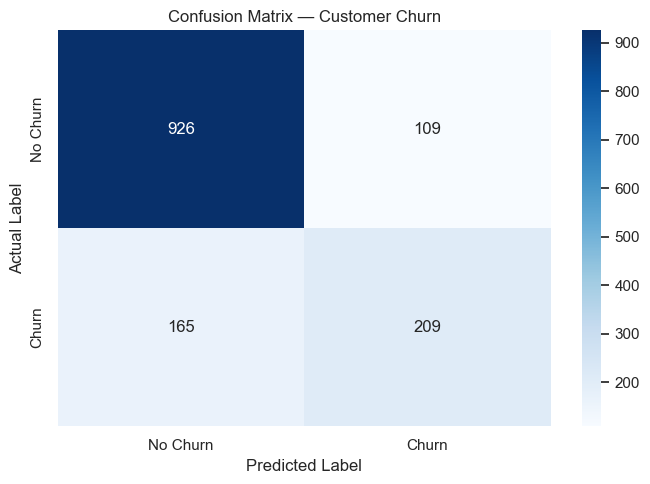

Confusion matrix saved.


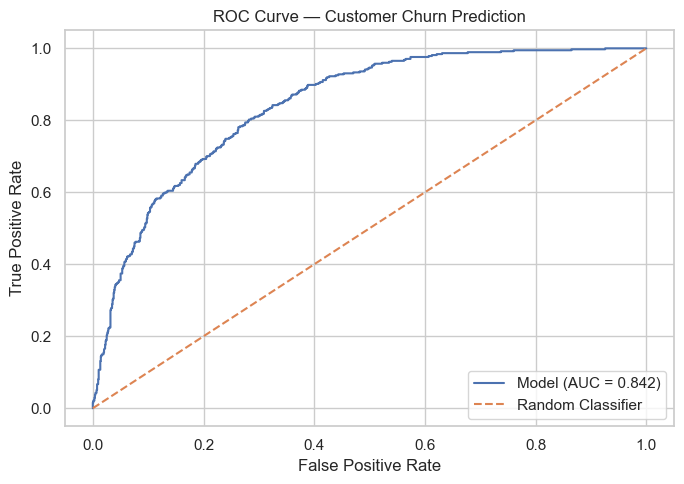

ROC curve saved.

Evaluation metrics saved to: c:\Users\VAISHNAVI V\Desktop\final internship poject\Customer_Intelligence_Predictive_Retention_Platform\reports\notebook_model_evaluation.csv

Optional comparison skipped: model_comparison.csv was not found.
The saved Logistic Regression model was evaluated independently.

NOTEBOOK 02 — EVALUATION COMPLETED
Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-score : 0.6040
ROC-AUC  : 0.8421

Reports folder: c:\Users\VAISHNAVI V\Desktop\final internship poject\Customer_Intelligence_Predictive_Retention_Platform\reports
Generated evaluation file: notebook_model_evaluation.csv
Generated confusion matrix: confusion_matrix.png
Generated ROC curve: roc_curve.png


In [1]:

# Customer Intelligence & Predictive Retention Platform
# Notebook 02 — Model Evaluation (Single-Cell Version)

from pathlib import Path
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

# --------------------------------------------------
# 1. FIND PROJECT ROOT AND FILES
# --------------------------------------------------

cwd = Path.cwd()

if (cwd / "data").exists() and (cwd / "models").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists() and (cwd.parent / "models").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Project root not found. Open this notebook from the project "
        "folder or its notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_cleaned.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "churn_model.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Cleaned dataset exists:", DATA_PATH.exists())
print("Trained model exists:", MODEL_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {DATA_PATH}\n"
        "Please run the data preparation and training steps first."
    )

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}\n"
        "Please train and save the model before evaluation."
    )

# --------------------------------------------------
# 2. LOAD DATASET AND TRAINED MODEL
# --------------------------------------------------

df_eval = pd.read_csv(DATA_PATH)

print("\nDATASET LOADED")
print("=" * 50)
print("Rows:", df_eval.shape[0])
print("Columns:", df_eval.shape[1])
print("Column names:", df_eval.columns.tolist())
display(df_eval.head())

required_columns = {"customerID", "Churn"}
missing_columns = required_columns - set(df_eval.columns)

if missing_columns:
    raise ValueError(
        f"Required columns missing from cleaned dataset: {missing_columns}"
    )

# Recreate the same stratified test split used for training
X = df_eval.drop(columns=["customerID", "Churn"])
y = df_eval["Churn"].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError(
        "Unexpected values in Churn column. Expected only 'No' and 'Yes'."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = joblib.load(MODEL_PATH)

print("\nModel loaded successfully!")
print("Model type:", type(model).__name__)
print("Test records:", len(X_test))

# --------------------------------------------------
# 3. GENERATE PREDICTIONS
# --------------------------------------------------

predictions = model.predict(X_test)

if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(X_test)[:, 1]
elif hasattr(model, "decision_function"):
    decision_scores = model.decision_function(X_test)
    probabilities = None
else:
    probabilities = None

# --------------------------------------------------
# 4. CALCULATE EVALUATION METRICS
# --------------------------------------------------

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

if probabilities is not None:
    roc_auc = roc_auc_score(y_test, probabilities)
elif "decision_scores" in locals():
    roc_auc = roc_auc_score(y_test, decision_scores)
else:
    roc_auc = np.nan

evaluation_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "ROC_AUC": roc_auc
}

evaluation_df = pd.DataFrame([evaluation_metrics])

print("\nMODEL EVALUATION RESULTS")
print("=" * 50)
display(evaluation_df.round(4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

# --------------------------------------------------
# 5. CONFUSION MATRIX
# --------------------------------------------------

cm = confusion_matrix(y_test, predictions, labels=[0, 1])

print("\nCONFUSION MATRIX")
print("Rows = Actual; Columns = Predicted")
print("Class 0 = No Churn; Class 1 = Churn")
print(cm)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    ax=ax
)
ax.set_title("Confusion Matrix — Customer Churn")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
fig.tight_layout()
fig.savefig(
    REPORTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Confusion matrix saved.")

# --------------------------------------------------
# 6. ROC CURVE
# --------------------------------------------------

if probabilities is not None or "decision_scores" in locals():
    scores = probabilities if probabilities is not None else decision_scores
    fpr, tpr, _ = roc_curve(y_test, scores)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(fpr, tpr, label=f"Model (AUC = {roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    ax.set_title("ROC Curve — Customer Churn Prediction")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(
        REPORTS_DIR / "roc_curve.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
    print("ROC curve saved.")
else:
    print("ROC curve skipped: model has no probability or decision scores.")

# --------------------------------------------------
# 7. SAVE EVALUATION METRICS
# --------------------------------------------------

evaluation_path = REPORTS_DIR / "notebook_model_evaluation.csv"
evaluation_df.to_csv(evaluation_path, index=False)

print("\nEvaluation metrics saved to:", evaluation_path)

# --------------------------------------------------
# 8. OPTIONAL: MODEL COMPARISON
# --------------------------------------------------

comparison_path = REPORTS_DIR / "model_comparison.csv"

if comparison_path.exists():
    model_results = pd.read_csv(comparison_path)

    print("\nMODEL COMPARISON RESULTS")
    print("=" * 50)
    print("Available columns:", model_results.columns.tolist())
    display(model_results)

    possible_name_cols = [
        "Model", "model", "Model_Name", "model_name", "Algorithm"
    ]
    model_col = next(
        (col for col in possible_name_cols if col in model_results.columns),
        None
    )

    metric_candidates = [
        "Accuracy", "Precision", "Recall",
        "F1_Score", "F1-Score", "ROC_AUC",
        "accuracy", "precision", "recall", "f1", "f1_score", "roc_auc"
    ]
    metric_cols = [
        col for col in metric_candidates if col in model_results.columns
    ]

    if model_col and metric_cols:
        comparison = model_results[[model_col] + metric_cols].copy()
        comparison = comparison.set_index(model_col)
        comparison = comparison.apply(pd.to_numeric, errors="coerce")

        display(comparison)

        ax = comparison.plot(kind="bar", figsize=(12, 6))
        ax.set_title("Machine Learning Model Performance Comparison")
        ax.set_xlabel("Model")
        ax.set_ylabel("Metric Score")
        ax.set_ylim(0, 1)
        plt.xticks(rotation=30, ha="right")
        plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

        f1_col = next(
            (
                col for col in ["F1_Score", "F1-Score", "f1_score", "f1"]
                if col in model_results.columns
            ),
            None
        )

        if f1_col:
            ranked = model_results.copy()
            ranked[f1_col] = pd.to_numeric(ranked[f1_col], errors="coerce")
            ranked = ranked.dropna(subset=[f1_col]).sort_values(
                f1_col, ascending=False
            )

            if not ranked.empty:
                print("\nMODELS RANKED BY F1-SCORE")
                display(ranked[[model_col, f1_col]].reset_index(drop=True))
                print("Best model:", ranked.iloc[0][model_col])
                print("Best F1-score:", round(ranked.iloc[0][f1_col], 4))
    else:
        print("Comparison skipped: model or metric columns not recognised.")
else:
    print(
        "\nOptional comparison skipped: model_comparison.csv was not found."
    )
    print("The saved Logistic Regression model was evaluated independently.")

# --------------------------------------------------
# 9. FINAL SUMMARY
# --------------------------------------------------

print("\nNOTEBOOK 02 — EVALUATION COMPLETED")
print("=" * 50)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}" if not np.isnan(roc_auc) else "ROC-AUC  : unavailable")
print("\nReports folder:", REPORTS_DIR)
print("Generated evaluation file:", evaluation_path.name)
print("Generated confusion matrix: confusion_matrix.png")
if (REPORTS_DIR / "roc_curve.png").exists():
    print("Generated ROC curve: roc_curve.png")
